# P8.13 — Butterworth analógico passa-baixas em forma de cascata

*IIR · protótipo analógico · Butterworth · cascata*

> Notebook gerado de `content/p8_13.py`, a mesma fonte da aplicação DSP Filter Lab e do relatório PDF. Para alterar o texto, edite o conteúdo e rode `tools/run_notebook.sh p8_13`.

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Enunciado original

> *Design an analog Butterworth lowpass filter that has a 0.5 dB or better ripple at 10 kHz and at least 45 dB of attenuation at 20 kHz. Determine the system function in a cascade form. Plot the magnitude response, the log-magnitude response in dB, the group-delay, and the impulse response of the filter.*

Fonte: DTA §2.2 item 10 e §4 (Resolução P8.13, com errata em θ_k); Ingle & Proakis, p. 465.

## 2. O que está sendo pedido


Projetar um **filtro analógico passa-baixas de Butterworth**, o protótipo contínuo que os métodos do Capítulo 8 depois convertem em filtro digital, que:

- perca **no máximo 0.5 dB** até 10 kHz (faixa de passagem);
- atenue **pelo menos 45 dB** a partir de 20 kHz (faixa de rejeição).

O resultado deve ser dado como **função de sistema em cascata**, ou seja, um produto de seções de 1ª e 2ª ordem. São pedidos quatro gráficos: magnitude, magnitude em dB, **atraso de grupo** e resposta ao impulso.

Na prática, é preciso encontrar a **menor ordem** $N$ que atende às duas exigências, a frequência de corte $\Omega_c$, os polos e a fatoração em seções.

## 3. Dados e especificações

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $F_p$ | 10 kHz | ■ Dado do enunciado | borda da faixa de passagem |
| $R_p$ | 0.5 dB | ■ Dado do enunciado | perda máxima admitida até $F_p$ |
| $F_s$ | 20 kHz | ■ Dado do enunciado | borda da faixa de rejeição |
| $A_s$ | 45 dB | ■ Dado do enunciado | atenuação mínima exigida a partir de $F_s$ |
| Aproximação | Butterworth | ■ Dado do enunciado | imposta pelo enunciado |
| Forma | cascata | ■ Dado do enunciado | forma pedida para a função de sistema |


O enunciado dá as frequências em **hertz**. As fórmulas do Butterworth usam frequência angular, então a conversão $\Omega = 2\pi F$ é o primeiro cálculo da resolução.

## 4. Fundamentação teórica


**Resposta maximamente plana.** O Butterworth de ordem $N$ é definido pela magnitude ao quadrado

$$|H_a(j\Omega)|^2 = \frac{1}{1 + (\Omega/\Omega_c)^{2N}}.$$

Em $\Omega = 0$, as primeiras $2N-1$ derivadas são nulas. A curva é a mais plana possível na origem e decresce **monotonicamente**, sem ondulações. Em $\Omega = \Omega_c$ a magnitude vale $1/\sqrt{2}$ ($-3$ dB). Quanto maior $N$, mais abrupta a queda: $20N$ dB por década na rejeição.

**Onde ficam os polos.** Os polos de $H_a(s)H_a(-s)$ são as raízes de $1 + (s/j\Omega_c)^{2N} = 0$: $2N$ pontos igualmente espaçados num círculo de raio $\Omega_c$. Para o filtro ser **estável**, $H_a(s)$ fica só com os $N$ polos do semiplano esquerdo, espaçados de $180°/N$.

**Por que cascata.** Polos complexos aparecem em pares conjugados $p, p^*$, e cada par forma um polinômio real de 2ª ordem (um **biquad**). Com $N$ ímpar sobra um polo real, que forma uma seção de 1ª ordem. A forma em cascata é a usada na prática, porque a forma racional de ordem alta tem coeficientes com enorme faixa dinâmica (aqui, o termo constante seria $\Omega_c^{9} \approx 4.37\times10^{43}$) e é numericamente frágil.


#### Aprofundamento: De onde vem a fórmula da ordem $N$?


Impondo as duas exigências com igualdade:

$$1 + \left(\frac{\Omega_p}{\Omega_c}\right)^{2N} = 10^{R_p/10}, \qquad 1 + \left(\frac{\Omega_s}{\Omega_c}\right)^{2N} = 10^{A_s/10}.$$

Dividindo uma pela outra, $\Omega_c$ desaparece e resta $(\Omega_p/\Omega_s)^{2N} = (10^{R_p/10}-1)/(10^{A_s/10}-1)$. Tomando $\log_{10}$ e isolando $N$, obtém-se a fórmula usada. Como $N$ precisa ser inteiro, arredonda-se **para cima**, e por isso sobra folga em pelo menos uma das bordas.


#### Aprofundamento: Por que escolher $\Omega_c$ pela borda de passagem?


Com $N$ arredondado para cima, há um intervalo de valores de $\Omega_c$ que atendem às duas bordas. O livro (função `afd_butt`, conforme o DTA) escolhe $\Omega_c$ para atender $R_p$ **exatamente** em $\Omega_p$. Toda a folga do arredondamento fica na rejeição. É uma convenção, não uma imposição do enunciado, e a rotina `scipy.signal.buttord` adota o mesmo critério.


#### Aprofundamento: O que é o atraso de grupo?


$\tau(\Omega) = -d\phi/d\Omega$ é o atraso, em segundos, sofrido pela **envoltória** de um sinal de banda estreita centrado em $\Omega$. Se $\tau$ fosse constante, todas as componentes chegariam juntas, sem distorção de fase. No Butterworth, $\tau$ cresce perto do corte, de modo que componentes próximas a $F_c$ chegam mais atrasadas.

Para um filtro só com polos $p_k = \sigma_k + j\omega_k$, cada polo contribui com $\frac{-\sigma_k}{\sigma_k^2 + (\Omega - \omega_k)^2}$, um "pico" centrado em $\omega_k$ que fica mais alto e estreito quanto mais o polo se aproxima do eixo $j\Omega$.

## 5. Equações e variáveis

**(1) Conversão de frequência**

$$
\Omega = 2\pi F
$$

Hertz para radianos por segundo.

| Símbolo | Significado |
|---|---|
| $F$ | frequência (Hz) |
| $\Omega$ | frequência angular (rad/s) |

**(2) Ordem mínima** · *DTA §3.2.A*

$$
N = \left\lceil \frac{\log_{10}\left[(10^{R_p/10}-1)/(10^{A_s/10}-1)\right]}{2\log_{10}(\Omega_p/\Omega_s)} \right\rceil
$$

Menor ordem inteira que atende simultaneamente $R_p$ em $\Omega_p$ e $A_s$ em $\Omega_s$.

| Símbolo | Significado |
|---|---|
| $R_p, A_s$ | perda máxima e atenuação mínima (dB) |
| $\Omega_p, \Omega_s$ | bordas de passagem e de rejeição (rad/s) |

**(3) Frequência de corte (−3 dB)** · *DTA §3.2.A*

$$
\Omega_c = \frac{\Omega_p}{(10^{R_p/10}-1)^{1/(2N)}}
$$

Escolhida para que a perda em $\Omega_p$ seja exatamente $R_p$.

| Símbolo | Significado |
|---|---|
| $\Omega_c$ | frequência de corte de −3 dB (rad/s) |

**(4) Polos no semiplano esquerdo** · *DTA §3.2.A*

$$
p_k = \Omega_c\, e^{\,j\left[\frac{\pi}{2} + \frac{(2k+1)\pi}{2N}\right]}, \quad k = 0, \dots, N-1
$$

Igualmente espaçados de $\pi/N$ sobre o círculo de raio $\Omega_c$.

| Símbolo | Significado |
|---|---|
| $p_k$ | k-ésimo polo |

**(5) Forma em cascata (N ímpar)** · *Errata E6 (corrige o DTA §4)*

$$
H_a(s) = \frac{\Omega_c}{s + \Omega_c}\prod_{k=1}^{(N-1)/2}\frac{\Omega_c^2}{s^2 + 2\Omega_c\cos\theta_k\, s + \Omega_c^2}, \qquad \theta_k = \frac{k\pi}{N}
$$

Uma seção de 1ª ordem (polo real em $-\Omega_c$) e $(N-1)/2$ biquads, cada um com ganho unitário em $s = 0$.

| Símbolo | Significado |
|---|---|
| $\theta_k$ | ângulo do k-ésimo par de polos medido a partir do eixo real negativo |

**(6) Atraso de grupo (analítico)**

$$
\tau(\Omega) = -\frac{d\phi}{d\Omega} = \sum_k \frac{-\sigma_k}{\sigma_k^2 + (\Omega - \omega_k)^2}
$$

Soma das contribuições de cada polo $p_k = \sigma_k + j\omega_k$.

| Símbolo | Significado |
|---|---|
| $\phi(\Omega)$ | fase de $H_a(j\Omega)$ |
| $\sigma_k, \omega_k$ | partes real e imaginária do polo |

## 6. Resolução passo a passo

### Passo 1 — Converter as frequências para rad/s

As fórmulas usam frequência angular.

$$
\Omega_p = 2\pi \cdot 10000 = 62831.85\ \text{rad/s}, \qquad \Omega_s = 2\pi \cdot 20000 = 125663.71\ \text{rad/s}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Omega_p$ | 62831.85 rad/s | ∑ Valor calculado | borda de passagem |
| $\Omega_s$ | 125663.71 rad/s | ∑ Valor calculado | borda de rejeição |

### Passo 2 — Calcular os termos da fórmula da ordem

Numerador: a razão entre as exigências de passagem e de rejeição. Denominador: a razão entre as bordas, que só depende de $F_p/F_s = 0.5$.

$$
\frac{10^{0.05}-1}{10^{4.5}-1} = \frac{0.12202}{31621.78}, \qquad \log_{10}(\cdot) = -5.4136, \qquad 2\log_{10}(0.5) = -0.60206
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $10^{R_p/10}-1$ | 0.12202 | ∑ Valor calculado | termo de passagem |
| $10^{A_s/10}-1$ | 31621.78 | ∑ Valor calculado | termo de rejeição |

### Passo 3 — Determinar a ordem mínima

Dividindo os logaritmos e arredondando **para cima**, porque a ordem precisa ser inteira e não pode ficar abaixo do necessário:

$$
N = \left\lceil \frac{-5.4136}{-0.60206} \right\rceil = \lceil 8.9917 \rceil = 9
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $N$ | 9 | ● Resultado obtido | ordem mínima |

> ⚠️ $8.9917$ está muito perto do inteiro 9, então o arredondamento deixa **pouca folga** na rejeição. Isso é verificado no último passo.

### Passo 4 — Calcular a frequência de corte

Convenção do livro: atender $R_p$ exatamente em $\Omega_p$ (ver aprofundamento).

$$
\Omega_c = \frac{62831.85}{(0.12202)^{1/18}} = \frac{62831.85}{0.88970} = 70621.02\ \text{rad/s} \quad (F_c = 11239.68\ \text{Hz})
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\Omega_c$ | 70621.0233 rad/s | ∑ Valor calculado | corte de −3 dB |
| $\text{critério de } \Omega_c$ | $R_p$ exato em $\Omega_p$ | ◆ Parâmetro escolhido | convenção do livro (`afd_butt`) |

### Passo 5 — Localizar os polos

Com $N = 9$, os polos ficam espaçados de $180°/9 = 20°$ no semiplano esquerdo. Como $N$ é ímpar, um deles cai exatamente sobre o eixo real negativo:

| $k$ | ângulo de $p_k$ | a partir do eixo real negativo | $p_k$ (rad/s) |
|---|---|---|---|
| 0 | 100° | 80° | $-12\,263.2 + j69\,548.1$ |
| 1 | 120° | 60° | $-35\,310.5 + j61\,159.6$ |
| 2 | 140° | 40° | $-54\,098.8 + j45\,394.3$ |
| 3 | 160° | 20° | $-66\,362.1 + j24\,153.8$ |
| 4 | 180° | 0° | $-70\,621.0 + j0.0$ |
| 5 | 200° | 20° | $-66\,362.1 - j24\,153.8$ |
| 6 | 220° | 40° | $-54\,098.8 - j45\,394.3$ |
| 7 | 240° | 60° | $-35\,310.5 - j61\,159.6$ |
| 8 | 260° | 80° | $-12\,263.2 - j69\,548.1$ |

$$
p_k = 70621.02\; e^{\,j\left[\frac{\pi}{2} + \frac{(2k+1)\pi}{18}\right]}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| polo real | $-\Omega_c$ | ∑ Valor calculado | gera a seção de 1ª ordem |
| pares conjugados | 4 | ∑ Valor calculado | geram os biquads |

### Passo 6 — Formar as seções da cascata

Um par conjugado a um ângulo $\theta$ do eixo real negativo é $p = \Omega_c(-\cos\theta \pm j\sin\theta)$, e o produto $(s-p)(s-p^*)$ vale $s^2 + 2\Omega_c\cos\theta\,s + \Omega_c^2$. Os ângulos são **20°, 40°, 60°, 80°**, ou seja, $\theta_k = k\pi/9$. Cada numerador é igual ao termo constante do denominador, o que dá ganho 1 em $s = 0$.

| Seção | $\theta$ | Coef. de $s$: $2\Omega_c\cos\theta$ | Termo constante | Numerador |
|---|---|---|---|---|
| 1ª ordem | 0° | — | $70621.02$ | $70621.02$ |
| Biquad 1 | 20° | $1.327241\times10^{5}$ | $4.987329\times10^{9}$ | $4.987329\times10^{9}$ |
| Biquad 2 | 40° | $1.081977\times10^{5}$ | $4.987329\times10^{9}$ | $4.987329\times10^{9}$ |
| Biquad 3 | 60° | $70621.02$ | $4.987329\times10^{9}$ | $4.987329\times10^{9}$ |
| Biquad 4 | 80° | $24526.42$ | $4.987329\times10^{9}$ | $4.987329\times10^{9}$ |

$$
\theta_k = \frac{k\pi}{9},\ k = 1,\dots,4 \qquad \Longrightarrow \qquad G = 1
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\theta_k$ | 20°, 40°, 60°, 80° | ∑ Valor calculado | ângulos dos pares |
| $G$ | 1 | ● Resultado obtido | ganho global: $H_a(0) = 1$ |

> ⚠️ **Errata E6.** O DTA usa $\theta_k = (2k-1)\pi/18$ (10°, 30°, 50°, 70°). Essa é a fórmula para **N par**, em que não há polo real. Com $N = 9$, os ângulos corretos são $k\pi/9$.

### Passo 7 — Verificar as duas exigências e a minimalidade

Avaliando $|H_a(j\Omega)|$ nas bordas, e também o mesmo projeto com uma ordem a menos:

$$
-20\log_{10}|H_a(j\Omega_p)| = 0.5000\ \text{dB}, \quad -20\log_{10}|H_a(j\Omega_s)| = 45.05\ \text{dB}, \quad N=8:\ 39.03\ \text{dB}
$$

| Grandeza | Valor | Origem | Significado |
|---|---|---|---|
| $\text{perda em } F_p$ | 0.5000 dB | ● Resultado obtido | ≤ 0.5 dB (igualdade por construção) |
| $\text{atenuação em } F_s$ | 45.05 dB | ● Resultado obtido | ≥ 45 dB, folga de 0.05 dB |
| $N - 1 = 8$ | 39.03 dB | ✓ Critério de validação | < 45 dB: confirma que 9 é o mínimo |

## 7. Implementação computacional


O projeto segue as fórmulas do livro, implementadas explicitamente no pacote `dsp_av2`. As rotinas do SciPy entram só como verificação independente nos testes.

1. **Especificação** (`specs.P8_13`): frequências em Hz convertidas por $\Omega = 2\pi F$.
2. **Ordem e corte** (`butter_order`, `butter_cutoff`): passos 2 a 4.
3. **Polos** (`butter_poles`): passo 5. Coincidem com `scipy.signal.butter(..., analog=True)` em ~$10^{-13}$.
4. **Cascata** (`forms.cascade`): agrupa os pares conjugados em biquads com ganho DC unitário (passo 6). Um teste confirma que o produto das seções reproduz exatamente a resposta em frequência do filtro.
5. **Análise**: magnitude a partir dos polos (`freqs_zpk`), atraso de grupo pela fórmula analítica (conferida com $-d\phi/d\Omega$ numérico) e $h(t)$ por simulação, conferida com a transformada inversa de Laplace por resíduos.


| Função | O que faz |
|---|---|
| `dsp_av2.iir.prototypes.butter_order` | Passos 2–3: ordem mínima N |
| `dsp_av2.iir.prototypes.butter_cutoff` | Passo 4: Ω_c com R_p exato em Ω_p |
| `dsp_av2.iir.prototypes.butter_poles` | Passo 5: polos no semiplano esquerdo |
| `dsp_av2.iir.forms.cascade` | Passo 6: seções de 1ª e 2ª ordem |
| `dsp_av2.iir.analysis.group_delay` | Atraso de grupo analítico |
| `dsp_av2.validation.validate_analog_lowpass` | Passo 7: verificação das bordas e da minimalidade |

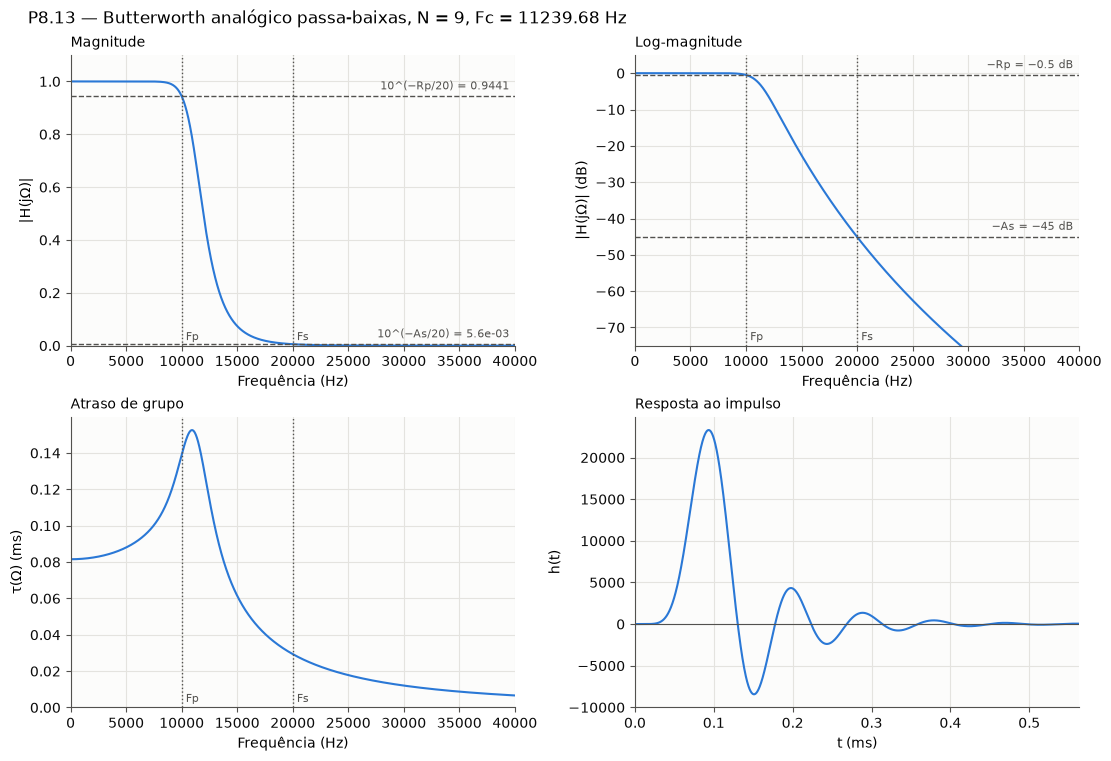

In [2]:
from content import p8_13 as content_mod
objs = content_mod.objects()
import matplotlib.pyplot as plt
from exercises import p8_13
fig = p8_13.plot(objs['proto'])
plt.show()

## 8. Gráficos e interpretação

### Polos no plano $s$


Os 9 polos ficam sobre o círculo de raio $\Omega_c$ ($F_c = 11.24$ kHz), espaçados de 20°, todos no semiplano esquerdo (filtro estável). O polo sobre o eixo real gera a seção de 1ª ordem, e cada par simétrico gera um biquad. Os ângulos medidos a partir do eixo real negativo, 20°, 40°, 60°, 80°, são os $\theta_k$ da cascata.


### Magnitude


Plana até perto de 10 kHz e decrescendo sem ondulações (monotônica). Em $F_p$ a magnitude vale $10^{-R_p/20}$, exatamente no limite, porque $\Omega_c$ foi escolhido assim.


### Magnitude em dB


A curva cruza $-0.5$ dB em 10 kHz e chega a $-45.05$ dB em 20 kHz, só 0.05 dB além do exigido, porque $N_{\text{real}} = 8.992$ quase não precisou ser arredondado.


### Atraso de grupo


Começa em 0.082 ms (DC) e chega a 0.153 ms perto de 10.9 kHz, junto ao corte. O pico vem do par de polos mais próximo do eixo $j\Omega$ (o de maior $\theta$). Componentes do sinal perto de $F_c$ sofrem atraso maior que as de baixa frequência.


### Resposta ao impulso


Oscilação amortecida com frequência próxima de $F_c$ (período ≈ $1/F_c$), que se extingue em menos de 1 ms. A oscilação é a "assinatura" no tempo dos polos complexos de baixo amortecimento.

## 9. Verificação das especificações


Três critérios: (1) a perda em toda a faixa $0 \le \Omega \le \Omega_p$ não excede $R_p$; (2) a atenuação em toda a faixa $\Omega_s \le \Omega \le 100\,\Omega_s$ é pelo menos $A_s$; (3) **minimalidade**: o mesmo projeto com ordem $N - 1$ não alcança $A_s$ em $\Omega_s$. As perdas são medidas em relação ao ganho máximo $|H_a(j0)| = 1$.

In [3]:
rep = objs.get('final_report') or objs.get('report')
print(rep)

Validação P8.13
  [OK  ] Perda máx. na passagem [dB]: 0.5000 <= 0.5000  (folga +0.0000)
  [OK  ] Atenuação mín. na rejeição [dB]: 45.0498 >= 45.0000  (folga +0.0498)
  [OK  ] Atenuação em Ωs com N−1 = 8 [dB] (deve falhar): 39.0296 <= 45.0000  (folga +5.9704)
  Resultado: ATENDE à especificação


## 10. Conclusão técnica


- Ordem mínima **$N = 9$** ($\lceil 8.9917 \rceil$) e corte **$\Omega_c = 70621.02$ rad/s** ($F_c = 11239.68$ Hz).
- Cascata: uma seção de 1ª ordem $\Omega_c/(s + \Omega_c)$ e 4 biquads com $\theta_k = k\pi/9$ (20°, 40°, 60°, 80°), com ganho global $G = 1$.
- Perda de 0.5000 dB em 10 kHz (igual ao limite, por construção) e atenuação de 45.05 dB em 20 kHz. Com $N = 8$ seriam 39.03 dB, insuficiente.
- **Correção do DTA (E6):** os ângulos $(2k-1)\pi/18$ do DTA valem para ordem par. Para $N = 9$, o correto é $k\pi/9$.